In [ ]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df= pd.read_csv('ovariantotal.csv')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349 entries, 0 to 348
Data columns (total 50 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   AFP        349 non-null    float64
 1   AG         349 non-null    float64
 2   Age        349 non-null    int64  
 3   ALB        349 non-null    float64
 4   ALP        349 non-null    int64  
 5   ALT        349 non-null    int64  
 6   AST        349 non-null    int64  
 7   BASO#      349 non-null    float64
 8   BASO%      349 non-null    float64
 9   BUN        349 non-null    float64
 10  Ca         349 non-null    float64
 11  CA125      349 non-null    float64
 12  CA19-9     349 non-null    float64
 13  CA72-4     349 non-null    float64
 14  CEA        349 non-null    float64
 15  CL         349 non-null    float64
 16  CO2CP      349 non-null    float64
 17  CREA       349 non-null    float64
 18  DBIL       349 non-null    float64
 19  EO#        349 non-null    float64
 20  EO%       

In [ ]:
df.head()

,AFP,AG,Age,ALB,ALP,ALT,AST,BASO#,BASO%,BUN,...,PCT,PDW,PHOS,PLT,RBC,RDW,TBIL,TP,UA,TYPE
0,3.58,19.36,47,45.4,56,11,24,0.01,0.30,5.35,...,0.09,13.4,1.46,74,2.64,13.7,5.5,73.9,396.4,0
1,34.24,23.98,61,39.9,95,9,13,0.02,0.30,3.21,...,0.30,11.2,1.09,304,4.89,12.7,6.8,72.0,119.2,0
2,1.50,18.40,39,45.4,77,9,18,0.03,0.60,3.80,...,0.13,15.2,0.97,112,4.62,12.0,14.8,77.9,209.2,0
3,2.75,16.60,45,39.2,26,16,17,0.05,0.74,5.27,...,0.25,17.4,1.25,339,4.01,14.6,10.9,66.1,215.6,0
4,2.36,19.97,45,35.0,47,21,27,0.01,0.10,4.89,...,0.28,11.9,0.94,272,4.40,13.4,5.3,66.5,206.0,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349 entries, 0 to 348
Data columns (total 50 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   AFP        349 non-null    float64
 1   AG         349 non-null    float64
 2   Age        349 non-null    int64  
 3   ALB        349 non-null    float64
 4   ALP        349 non-null    int64  
 5   ALT        349 non-null    int64  
 6   AST        349 non-null    int64  
 7   BASO#      349 non-null    float64
 8   BASO%      349 non-null    float64
 9   BUN        349 non-null    float64
 10  Ca         349 non-null    float64
 11  CA125      349 non-null    float64
 12  CA19-9     349 non-null    float64
 13  CA72-4     349 non-null    float64
 14  CEA        349 non-null    float64
 15  CL         349 non-null    float64
 16  CO2CP      349 non-null    float64
 17  CREA       349 non-null    float64
 18  DBIL       349 non-null    float64
 19  EO#        349 non-null    float64
 20  EO%       

In [ ]:
X=df.drop('TYPE',axis=1)
y=df['TYPE']

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=2)

# SINGLE CLASSIFIERS

# LogisticRegression

In [ ]:
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression(max_iter=21)
logreg.fit(X_train,y_train)
pred_y_logreg = logreg.predict(X_test)
from sklearn.metrics import confusion_matrix, classification_report , accuracy_score
print(confusion_matrix(y_test,pred_y_logreg))
print(accuracy_score(y_test,pred_y_logreg))
print(classification_report(y_test,pred_y_logreg))

[[39  5]
 [ 4 40]]
0.8977272727272727
              precision    recall  f1-score   support

           0       0.91      0.89      0.90        44
           1       0.89      0.91      0.90        44

    accuracy                           0.90        88
   macro avg       0.90      0.90      0.90        88
weighted avg       0.90      0.90      0.90        88



In [ ]:
# from sklearn.model_selection import cross_val_score, KFold
# kf = KFold(n_splits=2, shuffle=True, random_state=42)
# cv_scores = cross_val_score(logreg, X_train, y_train, cv=kf, scoring='accuracy')
# print("Cross-Validation Scores:", cv_scores)
# print("mean accuracy of logistic regression:", np.mean(cv_scores))

# KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train,y_train)
pred_y_knn= knn.predict(X_test)
from sklearn.metrics import confusion_matrix, classification_report , accuracy_score
print(confusion_matrix(y_test,pred_y_knn))
print(accuracy_score(y_test,pred_y_knn))
print(classification_report(y_test,pred_y_knn))

[[36  8]
 [ 6 38]]
0.8409090909090909
              precision    recall  f1-score   support

           0       0.86      0.82      0.84        44
           1       0.83      0.86      0.84        44

    accuracy                           0.84        88
   macro avg       0.84      0.84      0.84        88
weighted avg       0.84      0.84      0.84        88



# svm

In [ ]:
from sklearn import svm
clf=svm.SVC(kernel='linear',C=0.004,decision_function_shape='ovr')
clf.fit(X_train,y_train)
pred_y_svm_lin =clf.predict(X_test)
print(confusion_matrix(y_test,pred_y_svm_lin))
print(accuracy_score(y_test,pred_y_svm_lin))
print(classification_report(y_test,pred_y_svm_lin))

[[38  6]
 [ 5 39]]
0.875
              precision    recall  f1-score   support

           0       0.88      0.86      0.87        44
           1       0.87      0.89      0.88        44

    accuracy                           0.88        88
   macro avg       0.88      0.88      0.87        88
weighted avg       0.88      0.88      0.87        88



In [ ]:
from sklearn import svm
clf=svm.SVC(kernel='poly',)
clf.fit(X_train,y_train)
pred_y_svm =clf.predict(X_test)
print(confusion_matrix(y_test,pred_y_svm))
print(accuracy_score(y_test,pred_y_svm))
print(classification_report(y_test,pred_y_svm))

[[17 27]
 [ 2 42]]
0.6704545454545454
              precision    recall  f1-score   support

           0       0.89      0.39      0.54        44
           1       0.61      0.95      0.74        44

    accuracy                           0.67        88
   macro avg       0.75      0.67      0.64        88
weighted avg       0.75      0.67      0.64        88



In [ ]:
from sklearn import svm
clf=svm.SVC(kernel='rbf',C=0.9)
clf.fit(X_train,y_train)
pred_y_svm =clf.predict(X_test)
print(confusion_matrix(y_test,pred_y_svm))
print(accuracy_score(y_test,pred_y_svm))
print(classification_report(y_test,pred_y_svm))

[[31 13]
 [ 5 39]]
0.7954545454545454
              precision    recall  f1-score   support

           0       0.86      0.70      0.78        44
           1       0.75      0.89      0.81        44

    accuracy                           0.80        88
   macro avg       0.81      0.80      0.79        88
weighted avg       0.81      0.80      0.79        88



In [ ]:
from sklearn import svm
clf=svm.SVC(kernel='sigmoid',C=0.9)
clf.fit(X_train,y_train)
pred_y_svm =clf.predict(X_test)
print(confusion_matrix(y_test,pred_y_svm))
print(accuracy_score(y_test,pred_y_svm))
print(classification_report(y_test,pred_y_svm))

[[33 11]
 [ 8 36]]
0.7840909090909091
              precision    recall  f1-score   support

           0       0.80      0.75      0.78        44
           1       0.77      0.82      0.79        44

    accuracy                           0.78        88
   macro avg       0.79      0.78      0.78        88
weighted avg       0.79      0.78      0.78        88



# DT

In [ ]:
from sklearn.tree import DecisionTreeClassifier
dtree=  DecisionTreeClassifier(criterion="gini",ccp_alpha=0.06,min_samples_split=5, min_samples_leaf=5)
dtree.fit(X_train,y_train)
pred_y_dt =dtree.predict(X_test)
print(confusion_matrix(y_test,pred_y_dt))
print(accuracy_score(y_test,pred_y_dt))
print(classification_report(y_test,pred_y_dt))

[[40  4]
 [12 32]]
0.8181818181818182
              precision    recall  f1-score   support

           0       0.77      0.91      0.83        44
           1       0.89      0.73      0.80        44

    accuracy                           0.82        88
   macro avg       0.83      0.82      0.82        88
weighted avg       0.83      0.82      0.82        88



# NB

In [ ]:
from sklearn.naive_bayes import GaussianNB

In [ ]:
nb_classifier = GaussianNB()
nb_classifier.fit(X_train, y_train)
pred_y_nb = nb_classifier.predict(X_test)
print(confusion_matrix(y_test,pred_y_nb))
print(accuracy_score(y_test,pred_y_nb))
print(classification_report(y_test,pred_y_nb))

[[34 10]
 [ 3 41]]
0.8522727272727273
              precision    recall  f1-score   support

           0       0.92      0.77      0.84        44
           1       0.80      0.93      0.86        44

    accuracy                           0.85        88
   macro avg       0.86      0.85      0.85        88
weighted avg       0.86      0.85      0.85        88



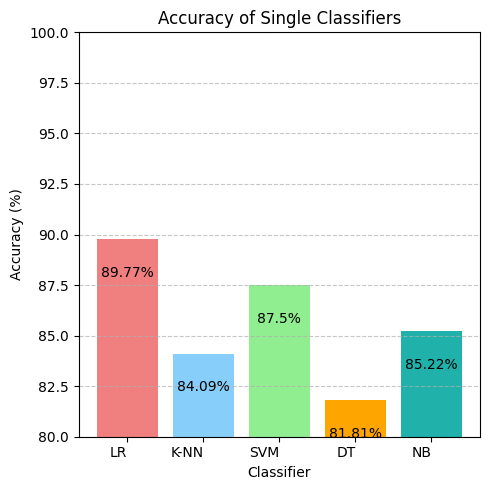

In [ ]:
import matplotlib.pyplot as plt

# Classifier names
classifiers = ['LR', 'K-NN', 'SVM', 'DT', 'NB']

# Accuracies
accuracies = [89.77, 84.09, 87.5, 81.81, 85.22]

# Define colors for bars
colors = ['lightcoral', 'lightskyblue', 'lightgreen', 'orange', 'lightseagreen']

# Plotting the bar graph
plt.figure(figsize=(5, 5))
bars = plt.bar(classifiers, accuracies, color=colors)

# Adding labels and title
plt.xlabel('Classifier')
plt.ylabel('Accuracy (%)')
plt.title('Accuracy of Single Classifiers')
plt.ylim(80, 100)  # Setting y-axis limits for better visualization

# Adding data labels on top of the bars
for bar, accuracy in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() - 2, f'{accuracy}%', ha='center', va='bottom')

# Displaying the plot
plt.xticks(rotation=0, ha='right')  # Rotate x-axis labels for better readability
plt.tight_layout()  # Adjust layout to prevent labels from being cut off
plt.grid(axis='y', linestyle='--', alpha=0.7)  # Add gridlines for better readability
plt.show()


# ENSEMBLE MODELS

# RF

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report , accuracy_score
rf_class = RandomForestClassifier(min_samples_split=2,n_estimators=50,max_features='sqrt',min_samples_leaf=35)
rf_class.fit(X_train,y_train)
y_pred_rf = rf_class.predict(X_test)
print(confusion_matrix(y_test,y_pred_rf))
print(accuracy_score(y_test,y_pred_rf))
print(classification_report(y_test,y_pred_rf))

[[38  6]
 [ 7 37]]
0.8522727272727273
              precision    recall  f1-score   support

           0       0.84      0.86      0.85        44
           1       0.86      0.84      0.85        44

    accuracy                           0.85        88
   macro avg       0.85      0.85      0.85        88
weighted avg       0.85      0.85      0.85        88



# BOOSTING

# GradientBoost

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
grad_boost = GradientBoostingClassifier(learning_rate=0.1)
grad_boost.fit(X_train,y_train)
y_pred_grad = grad_boost.predict(X_test)
from sklearn.metrics import confusion_matrix, classification_report , accuracy_score
print(confusion_matrix(y_test, y_pred_grad))
print(accuracy_score(y_test,y_pred_grad))
print(classification_report(y_test,y_pred_grad))

[[40  4]
 [ 9 35]]
0.8522727272727273
              precision    recall  f1-score   support

           0       0.82      0.91      0.86        44
           1       0.90      0.80      0.84        44

    accuracy                           0.85        88
   macro avg       0.86      0.85      0.85        88
weighted avg       0.86      0.85      0.85        88



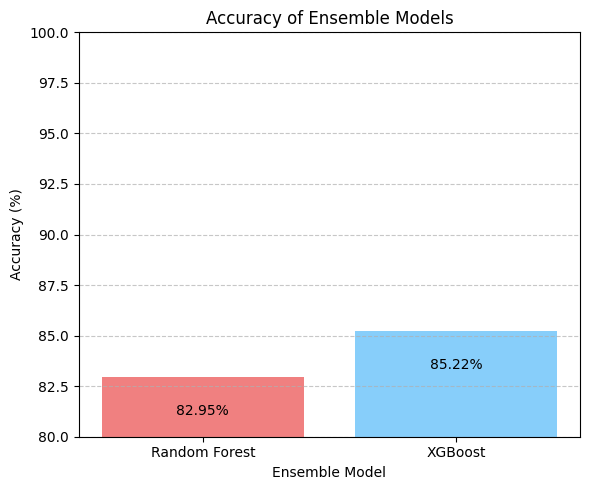

In [ ]:
import matplotlib.pyplot as plt

# Ensemble model names
ensemble_models = ['Random Forest', 'XGBoost']

# Accuracies
accuracies_ensemble = [82.95, 85.22]

# Define colors for bars
colors = ['lightcoral', 'lightskyblue', 'lightgreen', 'orange']

# Plotting the bar graph
plt.figure(figsize=(6, 5))
bars = plt.bar(ensemble_models, accuracies_ensemble, color=colors)

# Adding labels and title
plt.xlabel('Ensemble Model')
plt.ylabel('Accuracy (%)')
plt.title('Accuracy of Ensemble Models')
plt.ylim(80, 100)  # Setting y-axis limits for better visualization

# Adding data labels on top of the bars
for bar, accuracy in zip(bars, accuracies_ensemble):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() - 2, f'{accuracy}%', ha='center', va='bottom')

# Displaying the plot
plt.xticks(rotation=0, ha='center')  # Rotate x-axis labels for better readability
plt.tight_layout()  # Adjust layout to prevent labels from being cut off
plt.grid(axis='y', linestyle='--', alpha=0.7)  # Add gridlines for better readability
plt.show()


# Creating Own Ensemble model - SVM,RF AND XGB

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Each row represents one patient's predictions from the four classifiers
votes = np.column_stack((
    pred_y_logreg,
    pred_y_knn,
    pred_y_dt,
    pred_y_nb
))

# TYPE contains classes 0 and 1.
# With a 2–2 tie, predict class 0.
ensemble_pred = (votes.sum(axis=1) > 2).astype(int)

print("Max-voting ensemble")
print("Confusion matrix:\n", confusion_matrix(y_test, ensemble_pred))
print("Accuracy:", accuracy_score(y_test, ensemble_pred))
print(classification_report(y_test, ensemble_pred))

Max-voting ensemble
Confusion matrix:
 [[38  6]
 [ 5 39]]
Accuracy: 0.875
              precision    recall  f1-score   support

           0       0.88      0.86      0.87        44
           1       0.87      0.89      0.88        44

    accuracy                           0.88        88
   macro avg       0.88      0.88      0.87        88
weighted avg       0.88      0.88      0.87        88

